In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import os
import xarray as xr
import xcdat as xc

In [3]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker as mticker
import pandas as pd

In [4]:
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

ERROR 1: PROJ: proj_create_from_database: Open of /g/data/xp65/public/./apps/med_conda/envs/analysis3-25.09/share/proj failed


In [5]:
import cmocean
from scipy import stats

In [ ]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 14
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 0.8
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [ ]:
def plot_decorator():
    ax = plt.gca()
    
    # Minor ticks
    # ax.minorticks_on()
    # plt.tick_params(which='minor', axis='x', bottom=False)
    
    # Grid (light, behind data)
    ax.grid(color='gray', lw=0.4, alpha=0.1)
    
    # Remove top/right spines (Nature style)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Tight layout
    # plt.tight_layout()

In [ ]:
from matplotlib.colors import BoundaryNorm as BM
# from matplotlib.colors import LogNorm as LM
import matplotlib.patches as mpatches

In [9]:
import regionmask

In [10]:
def plot_background(ax, draw_labels=False, draw_ipcc_regions=False):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    # ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=draw_labels,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'color': 'k'}
    gl.ylabel_style = {'size': 10, 'color': 'k'}
    if draw_ipcc_regions:
        ar6_reg = regionmask.defined_regions.ar6.all

        # Plot the region boundaries, passing the same 'ax'
        # Use 'line_kws' to customize line properties (color, thickness, etc.)
        ar6_reg.plot_regions(
            ax=ax,
            line_kws=dict(color='black', lw=1.0, alpha=0.4),
            text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
            add_label=False, # Set to True to add text labels for regions
        )
    return ax




def plot_maps(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle', transform=ccrs.PlateCarree())
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='///', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] > 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] <= 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.01, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])



def plot_single_map(x, y, z, title, label, cmap, levels, add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(12,4), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
    if auto_aspect:
        ax.set_aspect('auto')
    
    cf=ax.contourf(x, y, z, cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
    if draw_winds:
        wind_separation = 5
        q = ax.quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd.to_numpy()[::wind_separation, ::wind_separation], v_wnd.to_numpy()[::wind_separation, ::wind_separation], scale=wind_scale, \
        color='k', transform=ccrs.PlateCarree())
        qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
        qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
    if draw_contour:
        ax.contour(x, y, contour_data, cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
    if land_mask_list:
        ax.add_feature(cfeature.LAND, color = 'k', zorder=1)
    if add_sign:
        if hatch_type == 'insig':
            pval_plot = np.ma.masked_less_equal(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='//', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval > 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        elif hatch_type == 'sig':
            pval_plot = np.ma.masked_greater(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='..', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval <= 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
    ax.set_title(title, fontdict={'fontsize':14})
    ax.text(0.01, 1.05, label, size=16, fontweight='bold', transform=ax.transAxes)
    if add_patch:
        ax.add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
    
    if add_patch_extra:
        ax.add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        plt.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = ax, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])

In [11]:
def plot_maps_no_proj(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_colorbar=True, auto_aspect=False, draw_clabel=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, sharex=True, sharey=True)
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle')
    
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            cs = axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, alpha=0.5)
            if draw_clabel:
                axlist[i].clabel(cs, inline=True, fontsize=8)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])
    return fig, axlist

In [12]:
def plot_maps_tele_delta(x, y, z, titles, labels, cmap, levels, pval = [], pval2=[], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, proj=ccrs.Robinson(central_longitude=160), 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle', transform=ccrs.PlateCarree())
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 1.5)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
        if pval2 != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 1.5)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='xxx', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval[i] <= 0.05, True, False)
            # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.01, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])



def plot_single_tele_delta(x, y, z, title, label, cmap, levels, add_sign=False, pval = [],  pval2 = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(12,4), land_mask_list = False, add_patch=False, add_patch_extra=False, proj=ccrs.Robinson(central_longitude=160), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
    if auto_aspect:
        ax.set_aspect('auto')
    
    cf=ax.contourf(x, y, z, cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
    if draw_winds:
        wind_separation = 5
        q = ax.quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd.to_numpy()[::wind_separation, ::wind_separation], v_wnd.to_numpy()[::wind_separation, ::wind_separation], scale=wind_scale, \
        color='k', transform=ccrs.PlateCarree())
        qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
        qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
    if draw_contour:
        ax.contour(x, y, contour_data, cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
    if land_mask_list:
        ax.add_feature(cfeature.LAND, color = 'k', zorder=1)
    if add_sign:
        pval_plot = np.ma.masked_less_equal(pval, 1)
        ax.pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
        pval_plot = np.ma.masked_less_equal(pval2, 1)
        ax.pcolor(x, y, pval_plot, alpha = 0., hatch='xxx', transform = ccrs.PlateCarree(central_longitude=0))
    ax.set_title(title, fontdict={'fontsize':14})
    ax.text(0.01, 1.05, label, size=16, fontweight='bold', transform=ax.transAxes)
    if add_patch:
        ax.add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
    
    if add_patch_extra:
        ax.add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        plt.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = ax, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])

In [13]:
import sys

In [14]:
# sys.path.append('./PhD/enso_teleconnection_robustness/')

In [15]:
from functions import preproc_funcs as funcs

In [16]:
model_list = [
    'ACCESS-ESM1-5',
    'CESM1-CAM5',
    'CSIRO-Mk3-6-0',
    'CanESM2',
    'CanESM5_p1',
    'GFDL-CM3',
    'GFDL-ESM2M',
    'GFDL-SPEAR-MED',
    'MIROC6',
    'MPI-ESM',
    
]

In [17]:
model_list_alt = [
    'ACCESS-ESM1-5',
    'CESM1-CAM5',
    'CESM2', # ssp3
    'CSIRO-Mk3-6-0',
    'CanESM2',
    'CanESM5_p1',
    'E3SM-1-0', # ssp3
    'E3SMv2', # ssp3
    'GFDL-CM3',
    'GFDL-ESM2M',
    'GFDL-SPEAR-MED',
    'MIROC6',
    'MPI-ESM',
    'UKESM1-0-LL', # ssp3
]

In [18]:
ts_regr_obs_baseline = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/tas_regr_obs_1950_2014.nc')
# ts_regr_rean_baseline = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/tas_regr_rean_1950_2014.nc')

ts_regr_obs_30y = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/tas_regr_30.nc')
ts_regr_obs_boot = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/tas_regr_boot.nc')
# ts_regr_rean_30y = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/tas_regr_30_rean.nc')

In [19]:
delta_ts_regr_obs = (ts_regr_obs_30y.regr - ts_regr_obs_baseline.regr)
# delta_ts_regr_rean = (ts_regr_rean_30y.regr - ts_regr_rean_baseline.regr)

In [20]:
plot_list = [
    ts_regr_obs_baseline.regr,
    ts_regr_obs_30y.regr.max('ey'),
    ts_regr_obs_30y.regr.min('ey'),
    # ts_regr_obs_30y.regr.var('ey'),
]

labels_list = [
    'a', 'b', 'c'#, 'd'
]

titles_list = [
    '$T - N3.4 (1950 - 2014)$',
    '$T - N3.4 (30y-max)$',
    '$T - N3.4 (30y-min)$',
    # '$P_\sigma ~ N3.4 (30y var)$',
]

pval_list = [
    ts_regr_obs_baseline.pval,
    np.ones_like(ts_regr_obs_baseline.pval),
    np.ones_like(ts_regr_obs_baseline.pval),
    # np.ones_like(ts_regr_obs_baseline.pval),
]


In [26]:
# ### Fractional model uncertainty in Base period and in mid century changes and end century changes

# xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)
# plot_maps(xx, yy, plot_list, titles_list, labels_list, cmap='RdBu_r', levels=np.linspace(-1, 1, 21), pval = pval_list, draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
#             nrows=1, ncols=3, figsize=(20,8), land_mask_list = [], add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.PlateCarree(central_longitude=180), 
#             cbar_kwargs=dict(orientation='horizontal', label='Regression (degC / degC)', aspect=45, shrink=0.5, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

In [27]:
# zz = plot_list[0]

# xx, yy = np.meshgrid(zz.lon, zz.lat)
# zz.


# plot_single_map(xx, yy, zz, title=titles_list[0], label='', cmap='RdBu_r', levels=np.linspace(-1, 1, 21), add_sign=False, pval = pval_list[0], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
#                 figsize=(7,8), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.PlateCarree(central_longitude=180), 
#                 cbar_kwargs=dict(orientation='horizontal', label='Standard deviation', aspect=40, shrink=1.1, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

<GeoAxes: title={'center': '$T - N3.4 (1950 - 2014)$'}, xlabel='lon', ylabel='lat'>

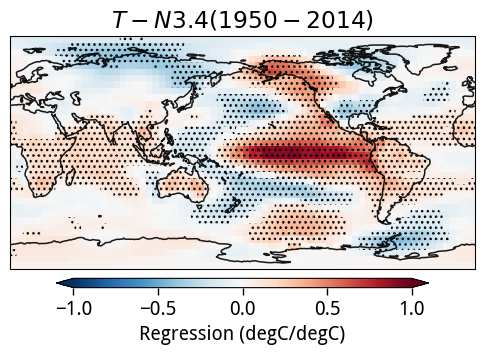

In [28]:
zz = plot_list[0]
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -1, vmax=1, extend='both', cmap='RdBu_r', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Regression (degC/degC)'), transform=ccrs.PlateCarree())
zp = np.ma.masked_greater_equal(pval_list[0], 0.05)
ax.pcolor(xx, yy, zp, alpha=0., hatch='...', transform=ccrs.PlateCarree())
ax.set_title(titles_list[0])
plot_background(ax)


<GeoAxes: title={'center': '$T - N3.4 (30y-max)$'}, xlabel='longitude [degrees_east]', ylabel='latitude [degrees_north]'>

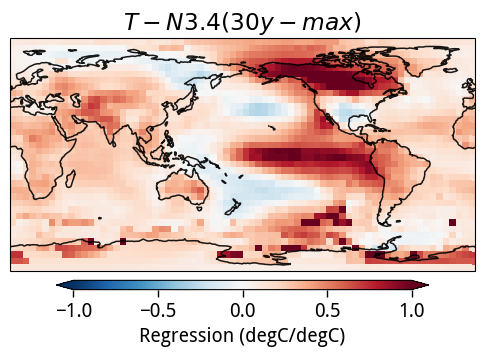

In [29]:
zz = plot_list[1]
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -1, vmax=1, extend='both', cmap='RdBu_r', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Regression (degC/degC)'), transform=ccrs.PlateCarree())
# zp = np.ma.masked_greater_equal(pval_list[0], 0.05)
# ax.pcolor(xx, yy, zp, alpha=0., hatch='...', transform=ccrs.PlateCarree())
ax.set_title(titles_list[1])
plot_background(ax)


<GeoAxes: title={'center': '$T - N3.4 (30y-min)$'}, xlabel='longitude [degrees_east]', ylabel='latitude [degrees_north]'>

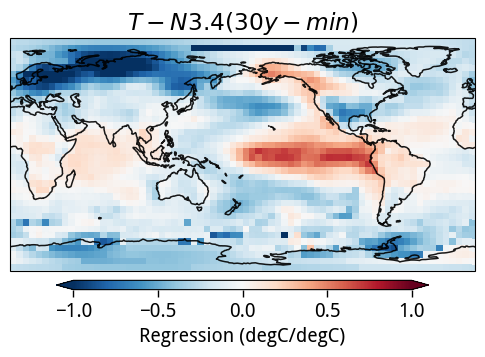

In [30]:
zz = plot_list[2]
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -1, vmax=1, extend='both', cmap='RdBu_r', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Regression (degC/degC)'), transform=ccrs.PlateCarree())
# zp = np.ma.masked_greater_equal(pval_list[0], 0.05)
# ax.pcolor(xx, yy, zp, alpha=0., hatch='...', transform=ccrs.PlateCarree())
ax.set_title(titles_list[2])
plot_background(ax)


In [31]:
# zz = ts_regr_obs_30y.regr.std('ey')

# xx, yy = np.meshgrid(zz.lon, zz.lat)


# plot_single_map(xx, yy, zz, title='$P_\sigma ~ N3.4 (30y var)$', label='d', cmap='viridis', levels=np.linspace(0, 0.4, 21), add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
#                 figsize=(7,8), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.PlateCarree(central_longitude=180), 
#                 cbar_kwargs=dict(orientation='horizontal', label='Standard deviation', aspect=40, shrink=1.1, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

<GeoAxes: title={'center': '$T - n3.4 (bootstrap-std.dev.)$'}, xlabel='longitude [degrees_east]', ylabel='latitude [degrees_north]'>

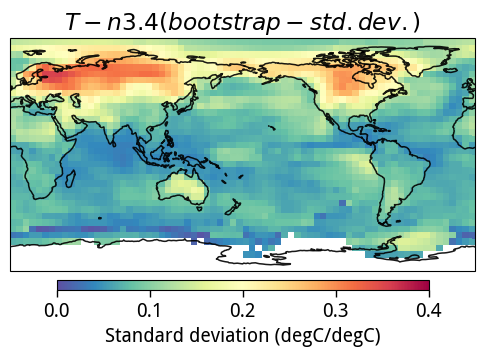

In [21]:

zz = ts_regr_obs_boot.regr.std('window')
# xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = 0, vmax=0.4, cmap='Spectral_r', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Standard deviation (degC/degC)'), transform=ccrs.PlateCarree())
# zp = np.ma.masked_greater_equal(pval_list[0], 0.05)
# ax.pcolor(xx, yy, zp, alpha=0., hatch='...', transform=ccrs.PlateCarree())
ax.set_title('$T - n3.4 (bootstrap-std.dev.)$')
plot_background(ax)


## precipitation

In [22]:
pr_regr_obs_baseline = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_obs_1950_2014.nc')
pr_regr_rean_baseline = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_rean_1950_2014.nc')

pr_regr_obs_30y = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_30.nc')
pr_regr_rean_30y = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_30_rean.nc')

In [23]:
pr_regr_obs_boot = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_boot.nc')
pr_regr_rean_boot = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_boot_rean.nc')

In [24]:
delta_pr_regr_obs = (pr_regr_obs_30y.regr - pr_regr_obs_baseline.regr)
delta_pr_regr_rean = (pr_regr_rean_30y.regr - pr_regr_rean_baseline.regr)

In [25]:
plot_list = [
    pr_regr_obs_baseline.regr,
    pr_regr_obs_30y.regr.max('ey'),
    pr_regr_obs_30y.regr.min('ey'),
    # pr_regr_obs_30y.regr.var('ey'),
]

labels_list = [
    'a', 'b', 'c'#, 'd'
]

titles_list = [
    '$P_\sigma - N3.4 (1950 - 2014)$',
    '$P_\sigma - N3.4 (30y-max)$',
    '$P_\sigma - N3.4 (30y-min)$',
    # '$P_\sigma ~ N3.4 (30y var)$',
]

pval_list = [
    pr_regr_obs_baseline.pval,
    np.ones_like(pr_regr_obs_baseline.pval),
    np.ones_like(pr_regr_obs_baseline.pval),
    # np.ones_like(pr_regr_obs_baseline.pval),
]


<GeoAxes: title={'center': '$P_\\sigma - N3.4 (1950 - 2014)$'}, xlabel='lon', ylabel='lat'>

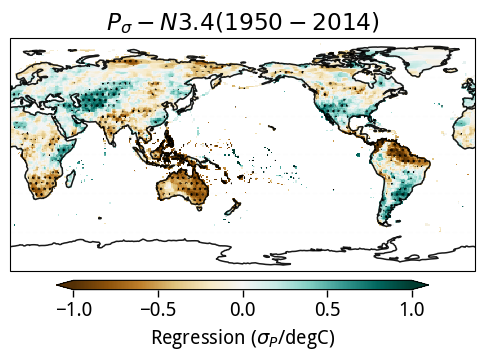

In [26]:
zz = plot_list[0]
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -1, vmax=1, extend='both', cmap='BrBG', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Regression ($\sigma_P$/degC)'), transform=ccrs.PlateCarree())
zp = np.ma.masked_greater_equal(pval_list[0], 0.05)
ax.pcolor(xx, yy, zp, alpha=0., hatch='...', transform=ccrs.PlateCarree())
ax.set_title(titles_list[0])
plot_background(ax)


<GeoAxes: title={'center': '$P_\\sigma - N3.4 (30y-max)$'}, xlabel='longitude [degrees_east]', ylabel='latitude [degrees_north]'>

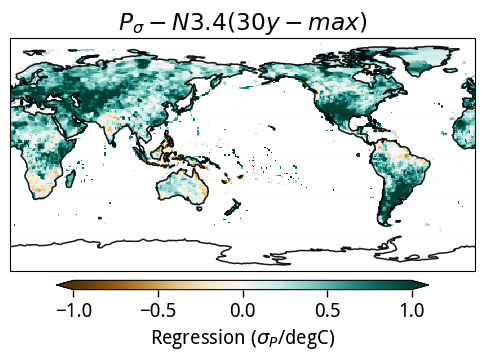

In [27]:
zz = plot_list[1]
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -1, vmax=1, extend='both', cmap='BrBG', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Regression ($\sigma_P$/degC)'), transform=ccrs.PlateCarree())
# zp = np.ma.masked_greater_equal(pval_list[0], 0.05)
# ax.pcolor(xx, yy, zp, alpha=0., hatch='...', transform=ccrs.PlateCarree())
ax.set_title(titles_list[1])
plot_background(ax)


<GeoAxes: title={'center': '$P_\\sigma - N3.4 (30y-min)$'}, xlabel='longitude [degrees_east]', ylabel='latitude [degrees_north]'>

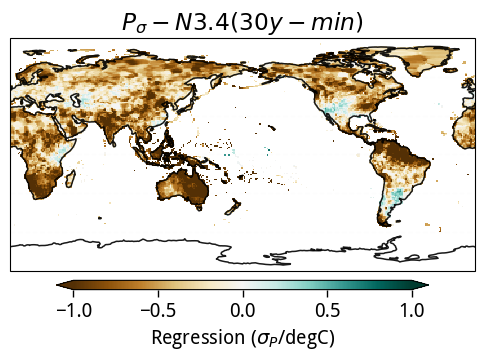

In [28]:
zz = plot_list[2]
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -1, vmax=1, extend='both', cmap='BrBG', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Regression ($\sigma_P$/degC)'), transform=ccrs.PlateCarree())
# zp = np.ma.masked_greater_equal(pval_list[0], 0.05)
# ax.pcolor(xx, yy, zp, alpha=0., hatch='...', transform=ccrs.PlateCarree())
ax.set_title(titles_list[2])
plot_background(ax)


In [29]:
# zz = pr_regr_obs_30y.regr.var('ey')

# xx, yy = np.meshgrid(zz.lon, zz.lat)


# plot_single_map(xx, yy, zz, title='$P_\sigma ~ N3.4 (30y var)$', label='d', cmap='viridis', levels=np.linspace(0, 0.2, 21), add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
#                 figsize=(7,8), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.PlateCarree(central_longitude=180), 
#                 cbar_kwargs=dict(orientation='horizontal', label='Variance', aspect=40, shrink=1.1, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

<GeoAxes: title={'center': '$p_\\sigma - N3.4 (bootstrap-std.dev.)$'}, xlabel='longitude [degrees_east]', ylabel='latitude [degrees_north]'>

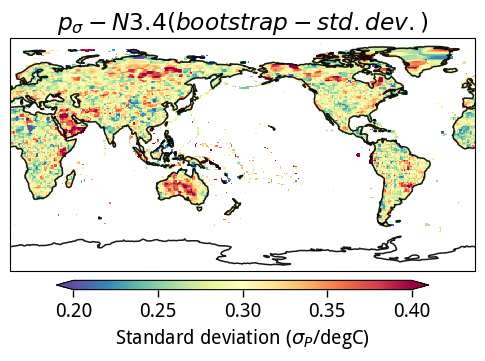

In [34]:
zz = pr_regr_obs_boot.regr.std('window')
# xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = 0.2, vmax=0.4, cmap='Spectral_r', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Standard deviation ($\sigma_P$/degC)'), transform=ccrs.PlateCarree())
# zp = np.ma.masked_greater_equal(pval_list[0], 0.05)
# ax.pcolor(xx, yy, zp, alpha=0., hatch='...', transform=ccrs.PlateCarree())
ax.set_title('$p_\sigma - N3.4 (bootstrap-std.dev.)$')
plot_background(ax)


In [35]:
plot_list = [
    pr_regr_rean_baseline.regr,
    pr_regr_rean_30y.regr.max('ey'),
    pr_regr_rean_30y.regr.min('ey'),
    # pr_regr_rean_30y.regr.var('ey'),
]

labels_list = [
    'a', 'b', 'c'#, 'd'
]

titles_list = [
    '$P_\sigma - N3.4 (1950 - 2014)$',
    '$P_\sigma - N3.4 (30y-max)$',
    '$P_\sigma - N3.4 (30y-min)$',
    # '$P_\sigma ~ N3.4 (30y var)$',
]

pval_list = [
    pr_regr_rean_baseline.pval,
    np.ones_like(pr_regr_rean_baseline.pval),
    np.ones_like(pr_regr_rean_baseline.pval),
    # np.ones_like(pr_regr_rean_baseline.pval),
]


In [36]:
# ### Fractional model uncertainty in Base period and in mid century changes and end century changes

# xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)
# plot_maps(xx, yy, plot_list, titles_list, labels_list, cmap='BrBG', levels=np.linspace(-1, 1, 21), pval = pval_list, draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
#             nrows=1, ncols=3, figsize=(20,8), land_mask_list = [], add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.PlateCarree(central_longitude=180), 
#             cbar_kwargs=dict(orientation='horizontal', label='Regression (mm std$^{-1}$ / degC)', aspect=45, shrink=0.5, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

In [37]:
# zz = pr_regr_rean_30y.regr.var('ey')

# xx, yy = np.meshgrid(zz.lon, zz.lat)


# plot_single_map(xx, yy, zz, title='$P_\sigma ~ N3.4 (30y var)$', label='d', cmap='viridis', levels=np.linspace(0, 0.2, 21), add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
#                 figsize=(7,8), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.PlateCarree(central_longitude=180), 
#                 cbar_kwargs=dict(orientation='horizontal', label='Variance', aspect=40, shrink=1.1, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

<GeoAxes: title={'center': '$P_\\sigma - N3.4 (1950 - 2014)$'}, xlabel='lon', ylabel='lat'>

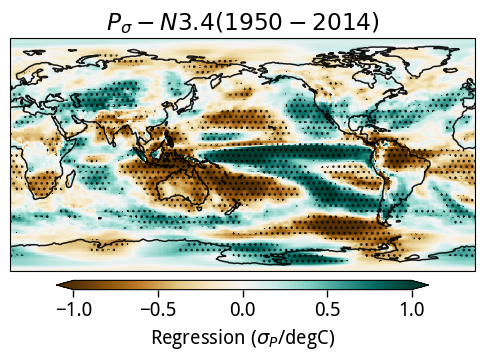

In [38]:
zz = plot_list[0]
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -1, vmax=1, extend='both', cmap='BrBG', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Regression ($\sigma_P$/degC)'), transform=ccrs.PlateCarree())
zp = np.ma.masked_greater_equal(pval_list[0], 0.05)
ax.pcolor(xx, yy, zp, alpha=0., hatch='...', transform=ccrs.PlateCarree())
ax.set_title(titles_list[0])
plot_background(ax)


<GeoAxes: title={'center': '$P_\\sigma - N3.4 (30y-max)$'}, xlabel='Longitude [degrees_east]', ylabel='Latitude [degrees_north]'>

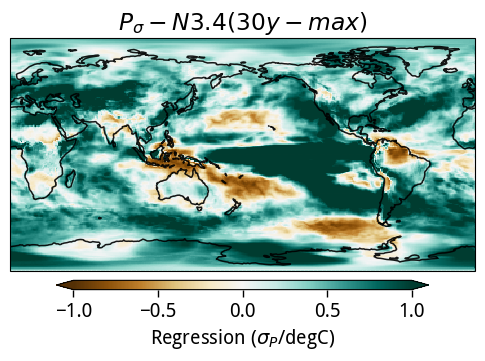

In [39]:
zz = plot_list[1]
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -1, vmax=1, extend='both', cmap='BrBG', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Regression ($\sigma_P$/degC)'), transform=ccrs.PlateCarree())
# zp = np.ma.masked_greater_equal(pval_list[0], 0.05)
# ax.pcolor(xx, yy, zp, alpha=0., hatch='...', transform=ccrs.PlateCarree())
ax.set_title(titles_list[1])
plot_background(ax)


<GeoAxes: title={'center': '$P_\\sigma - N3.4 (30y-min)$'}, xlabel='Longitude [degrees_east]', ylabel='Latitude [degrees_north]'>

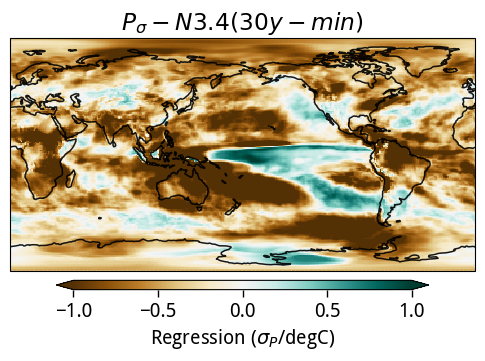

In [40]:
zz = plot_list[2]
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -1, vmax=1, extend='both', cmap='BrBG', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Regression ($\sigma_P$/degC)'), transform=ccrs.PlateCarree())
# zp = np.ma.masked_greater_equal(pval_list[0], 0.05)
# ax.pcolor(xx, yy, zp, alpha=0., hatch='...', transform=ccrs.PlateCarree())
ax.set_title(titles_list[2])
plot_background(ax)


<GeoAxes: title={'center': '$p_\\sigma - N3.4 (30y-std.dev.)$'}, xlabel='Longitude [degrees_east]', ylabel='Latitude [degrees_north]'>

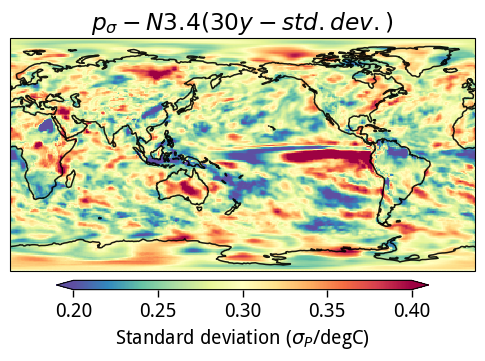

In [41]:
zz = pr_regr_rean_boot.regr.std('window')
# xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = 0.2, vmax=0.4, cmap='Spectral_r', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Standard deviation ($\sigma_P$/degC)'), transform=ccrs.PlateCarree())
# zp = np.ma.masked_greater_equal(pval_list[0], 0.05)
# ax.pcolor(xx, yy, zp, alpha=0., hatch='...', transform=ccrs.PlateCarree())
ax.set_title('$p_\sigma - N3.4 (30y-std.dev.)$')
plot_background(ax)


## regional variation

In [32]:
ersst = xr.open_mfdataset('/g/data/su28/MMLEAv2/observations/tos_ersstv5_g025_185401-202412.nc')
ersst['time'] = xr.cftime_range('1854-01-01', '2025-01-01', freq='1M')

hadisst = xr.open_mfdataset('/g/data/su28/MMLEAv2/observations/tos_hadisst_g025_187001-202412.nc')
hadisst['time'] = xr.cftime_range('1870-01-01', '2025-01-01', freq='1M')

In [33]:
ersst_det = funcs.detrend_rolling_window(funcs.calc_anom(ersst, ersst.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)
hadisst_det = funcs.detrend_rolling_window(funcs.calc_anom(hadisst, hadisst.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)

In [34]:
tas_obs = xr.open_mfdataset('/g/data/su28/MMLEAv2/observations/tas_hadcrut.5.0.2.0_g025_185001-202402.nc')
tas_obs['time'] = xr.cftime_range('1850-01-01', '2024-03-01', freq='1M')
pr_obs = xr.open_mfdataset('/g/data/su28/MMLEAv2/observations/pr_gpcc.10.v2022_g025_189101-202402.nc')
pr_obs['time'] = xr.cftime_range('1891-01-01', '2024-03-01', freq='1M')

In [35]:
# pr_era5 = xr.open_mfdataset('/g/data/su28/MMLEAv2/observations/pr_era5_g025_194001-202312.nc')
# pr_era5['time'] = xr.cftime_range('1940-01-01', '2024-01-01', freq='1M')

In [36]:
pr_rean = xr.open_mfdataset('/g/data/if69/as8561/data/20CR/precip/prate.mon.mean.nc')
pr_rean = pr_rean.rename(dict(prate = 'pr'))
pr_rean['time'] = xr.cftime_range('1836-01-01', '2016-01-01', freq='1M')
pr_rean

<xarray.Dataset> Size: 563MB
Dimensions:    (lat: 181, lon: 360, time: 2160, nbnds: 2)
Coordinates:
  * lat        (lat) float32 724B -90.0 -89.0 -88.0 -87.0 ... 88.0 89.0 90.0
  * lon        (lon) float32 1kB 0.0 1.0 2.0 3.0 4.0 ... 356.0 357.0 358.0 359.0
  * time       (time) object 17kB 1836-01-31 00:00:00 ... 2015-12-31 00:00:00
Dimensions without coordinates: nbnds
Data variables:
    time_bnds  (time, nbnds) float64 35kB dask.array<chunksize=(1, 2), meta=np.ndarray>
    pr         (time, lat, lon) float32 563MB dask.array<chunksize=(1, 181, 360), meta=np.ndarray>
Attributes: (12/24)
    Conventions:               CF-1.2
    title:                     Monthly NOAA/CIRES/DOE 20th Century Reanalysis V3
    comments:                  Data are from \nNOAA/CIRES/DOE 20th Century Re...
    standard_name_vocabulary:  NetCDF Climate and Forecast (CF) Metadata Conv...
    license:                   These data are available free of charge under ...
    spatial_resolution:        1.0 degree
    ...                        ...
    citation1:                 Slivinski, L. C, G. P. Compo, J. S. Whitaker, ...
    References:                https://www.psl.noaa.gov/data/gridded/data.20t...
    creator_name:              NOAA/PSL
    institution:               NOAA Physical Sciences Laboratory & CU/CIRES \...
    contact:                   psl.data@noaa.gov
    citation:                  Compo,G.P. <https://www.psl.noaa.gov/people/gi...

In [37]:
tas_obs_det = funcs.detrend_rolling_window(funcs.calc_anom(tas_obs, tas_obs.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)
pr_obs_det = funcs.detrend_rolling_window(funcs.calc_anom(pr_obs, pr_obs.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)
pr_rean_det = funcs.detrend_rolling_window(funcs.calc_anom(pr_rean, pr_rean.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)

In [38]:
# psl = xr.open_mfdataset('/g/data/if69/as8561/data/20CR/slp/prmsl.mon.mean.nc')
# psl = psl.rename(dict(prmsl = 'psl'))
# uwnd = xr.open_mfdataset('/g/data/if69/as8561/data/20CR/wind/uwnd.10m.mon.mean.nc')
# vwnd = xr.open_mfdataset('/g/data/if69/as8561/data/20CR/wind/vwnd.10m.mon.mean.nc')
# hgt = xr.open_mfdataset('/g/data/if69/as8561/data/20CR/hgt/hgt.mon.mean_500.nc')

In [39]:
# psl_det = funcs.detrend_rolling_window(funcs.calc_anom(psl, psl.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)
# uwnd_det = funcs.detrend_rolling_window(funcs.calc_anom(uwnd, uwnd.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)
# vwnd_det = funcs.detrend_rolling_window(funcs.calc_anom(vwnd, vwnd.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)
# hgt_det = funcs.detrend_rolling_window(funcs.calc_anom(hgt, hgt.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)

In [40]:
from dask.diagnostics import ProgressBar

In [41]:
with ProgressBar():
    ersst_det = ersst_det.tos.sel(time = slice('1900', '2014')).compute()
    hadisst_det = hadisst_det.tos.sel(time = slice('1900', '2014')).compute()
    tas_obs_det = tas_obs_det.tas.sel(time = slice('1900', '2014')).compute()
    pr_obs_det = pr_obs_det.pr.sel(time = slice('1900', '2014')).compute()
    pr_rean_det = pr_rean_det.pr.sel(time = slice('1900', '2014')).compute()

[########################################] | 100% Completed | 1.84 sms
[########################################] | 100% Completed | 1.74 sms
[########################################] | 100% Completed | 12.71 s
[########################################] | 100% Completed | 2.24 ss
[########################################] | 100% Completed | 11.19 s


In [42]:
# with ProgressBar():
#     psl_det = psl_det.psl.sel(time = slice('1900', '2014')).compute()
#     psl_det['time'] = pr_rean_det['time']
#     uwnd_det = uwnd_det.uwnd.sel(time = slice('1900', '2014')).compute()
#     uwnd_det['time'] = pr_rean_det['time']
#     vwnd_det = vwnd_det.vwnd.sel(time = slice('1900', '2014')).compute()
#     vwnd_det['time'] = pr_rean_det['time']
#     hgt_det = hgt_det.hgt.sel(time = slice('1900', '2014')).compute()
#     hgt_det['time'] = pr_rean_det['time']

In [43]:
pr_obs_std = pr_obs_det/pr_obs_det.std('time')
pr_rean_std = pr_rean_det/pr_rean_det.std('time')

In [44]:
pr_rean_std

<xarray.DataArray 'pr' (time: 115, lat: 181, lon: 360)> Size: 30MB
array([[[-0.282475  , -0.282475  , -0.282475  , ..., -0.282475  ,
         -0.282475  , -0.282475  ],
        [-0.15668504, -0.1503599 , -0.15630943, ..., -0.15972652,
         -0.15769635, -0.16777836],
        [-0.09038914, -0.09151712, -0.10576872, ..., -0.10767967,
         -0.11111484, -0.11233626],
        ...,
        [-0.10875204, -0.10709496, -0.11047538, ..., -0.10061551,
         -0.10568786, -0.11109946],
        [-0.20355771, -0.20261464, -0.19958377, ..., -0.19613436,
         -0.196644  , -0.19912545],
        [-0.24701141, -0.24701141, -0.24701141, ..., -0.24701141,
         -0.24701141, -0.24701141]],

       [[ 0.46080938,  0.46080938,  0.46080938, ...,  0.46080938,
          0.46080938,  0.46080938],
        [ 0.29817778,  0.3030413 ,  0.29455674, ...,  0.3074457 ,
          0.29914653,  0.30102062],
        [ 0.20668687,  0.21374084,  0.21157905, ...,  0.20880651,
          0.19600268,  0.20147993],
...
        [ 1.1457093 ,  1.1565455 ,  1.1787276 , ...,  1.0796652 ,
          1.1130645 ,  1.133194  ],
        [ 1.4977162 ,  1.5019453 ,  1.5047183 , ...,  1.4705197 ,
          1.4831054 ,  1.4861927 ],
        [ 1.7810166 ,  1.7810166 ,  1.7810166 , ...,  1.7810166 ,
          1.7810166 ,  1.7810166 ]],

       [[ 1.4870056 ,  1.4870056 ,  1.4870056 , ...,  1.4870056 ,
          1.4870056 ,  1.4870056 ],
        [ 1.2146847 ,  1.2215707 ,  1.2251503 , ...,  1.1953635 ,
          1.1907067 ,  1.2052119 ],
        [ 0.5425624 ,  0.54095423,  0.5724486 , ...,  0.515634  ,
          0.5244506 ,  0.5368324 ],
        ...,
        [ 2.4275744 ,  2.4337482 ,  2.4324756 , ...,  2.424981  ,
          2.4348595 ,  2.4265525 ],
        [ 2.412509  ,  2.4166374 ,  2.415178  , ...,  2.4056249 ,
          2.413907  ,  2.4092274 ],
        [ 1.7210498 ,  1.7210498 ,  1.7210498 , ...,  1.7210498 ,
          1.7210498 ,  1.7210498 ]]], dtype=float32)
Coordinates:
  * lat      (lat) float32 724B -90.0 -89.0 -88.0 -87.0 ... 87.0 88.0 89.0 90.0
  * lon      (lon) float32 1kB 0.0 1.0 2.0 3.0 4.0 ... 356.0 357.0 358.0 359.0
  * time     (time) object 920B 1900-06-01 00:00:00 ... 2014-06-01 00:00:00

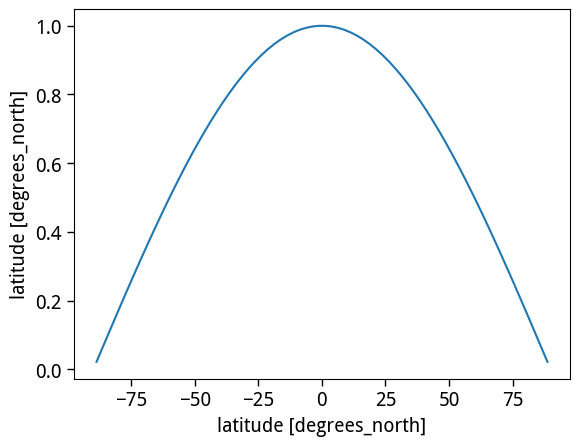

In [45]:
weights_obs = np.cos(np.deg2rad(hadisst_det.lat))
weights_obs.name = 'weights'
weights_obs.plot()

In [46]:
nino34_index_hadisst = hadisst_det.sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(weights_obs).mean(('lat', 'lon'))
nino34_index = nino34_index_hadisst
nino34_index_ersst = ersst_det.sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(weights_obs).mean(('lat', 'lon'))

In [47]:
import seaborn as sns

In [148]:
land_mask_ts = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(tas_obs_det)
ar6_mask_ts = regionmask.defined_regions.ar6.land.mask_3D(tas_obs_det.where(land_mask_ts))
# ar6_mask_ts = regionmask.defined_regions.ar6.all.mask_3D(tas_obs_det)

In [149]:
land_mask = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(pr_obs_std)
ar6_mask = regionmask.defined_regions.ar6.land.mask_3D(pr_obs_std.where(land_mask))
# ar6_mask = regionmask.defined_regions.ar6.all.mask_3D(pr_obs_std)

In [150]:
land_mask_rean = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(pr_rean_std)
ar6_mask_rean = regionmask.defined_regions.ar6.land.mask_3D(pr_rean_std.where(land_mask_rean))
# ar6_mask_rean = regionmask.defined_regions.ar6.all.mask_3D(pr_rean_std)

In [151]:
def calc_tele(precip: xr.DataArray, nino34: xr.DataArray, start_year: int, end_year: int):
    if not isinstance(precip, xr.DataArray) or not isinstance(nino34, xr.DataArray):
        raise TypeError("'xr.DataArray' input is required, not the %s" % (type(precip)))
    duration = end_year - start_year
    res = stats.linregress(nino34.sel(time=slice(str(start_year), str(end_year))), precip.sel(time=slice(str(start_year), str(end_year))))
    return res.slope, res.pvalue, duration


def get_all_tele(precip: xr.DataArray, nino34: xr.DataArray, initial_dur: int = 10):
    if not isinstance(precip, xr.DataArray) or not isinstance(nino34, xr.DataArray):
        raise TypeError("'xr.DataArray' input is required, not the %s" % (type(precip)))
    start_years = np.arange(1900, 2016, 2)
    end_years = np.arange(1900, 2016, 2)
    stat = np.empty((len(start_years), len(end_years)))
    pval = np.empty((len(start_years), len(end_years)))
    duration = np.empty((len(start_years), len(end_years)))
    for i in range(len(start_years)):
        for j in range(len(end_years)):
            if end_years[j] < start_years[i] + initial_dur:
                stat[i, j], pval[i, j], duration[i, j] = np.NaN, np.NaN, np.NaN
            else:
                stat[i, j], pval[i, j], duration[i, j] = calc_tele(precip, nino34, start_years[i], end_years[j])
        # print(f"Completed {start_years[i]}", end='\r')
    return start_years, end_years, stat, pval, duration


In [152]:
pr_obs

<xarray.Dataset> Size: 414MB
Dimensions:  (time: 1598, lon: 360, lat: 180)
Coordinates:
  * time     (time) object 13kB 1891-01-31 00:00:00 ... 2024-02-29 00:00:00
  * lon      (lon) float64 3kB -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
  * lat      (lat) float64 1kB 89.5 88.5 87.5 86.5 ... -86.5 -87.5 -88.5 -89.5
Data variables:
    pr       (time, lat, lon) float32 414MB dask.array<chunksize=(1598, 180, 360), meta=np.ndarray>
Attributes: (12/24)
    CDI:                       Climate Data Interface version 2.3.0 (https://...
    Conventions:               CF-1.4
    institution:               Deutscher Wetterdienst
    history:                   Fri Dec 06 23:24:14 2024: cdo chname,precip,pr...
    title:                     GPCC Full Data Monthly Product Version 2022, p...
    summary:                   The Full Data Monthly Product is of much highe...
    ...                        ...
    geospatial_lon_max:        180.
    NCO:                       "4.5.2"
    nco_openmp_thread_number:  1
    time_modification_script:  /project/cas/asphilli/DSets/GPCC/v2022_time-re...
    source_units_modify:       /glade/u/home/asphilli/Jan21/Various/mmlea.gpc...
    CDO:                       Climate Data Operators version 2.3.0 (https://...

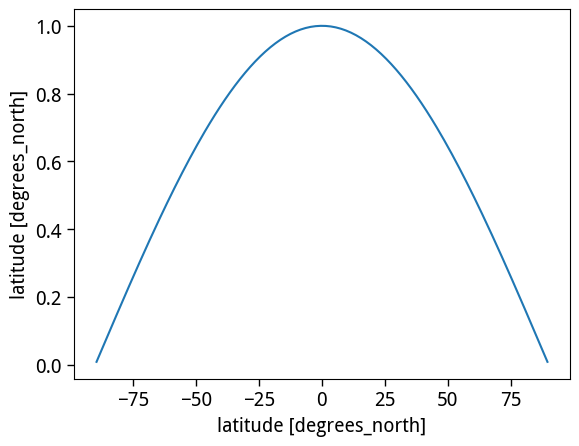

In [153]:
weights_pr_obs = np.cos(np.deg2rad(pr_obs_std.lat))
weights_pr_obs.name = 'weights'
weights_pr_obs.plot()

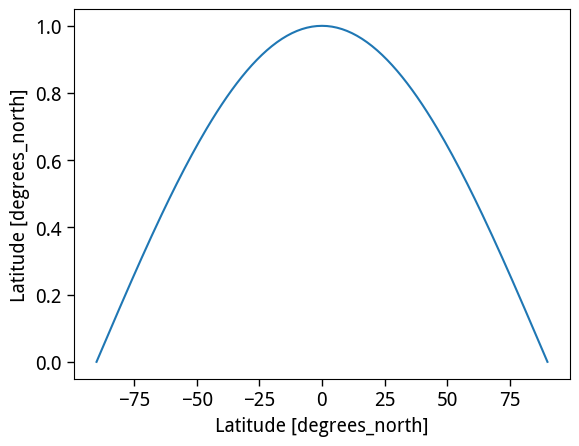

In [154]:
weights_pr_rean = np.cos(np.deg2rad(pr_rean_std.lat))
weights_pr_rean.name = 'weights'
weights_pr_rean.plot()

In [155]:
reg_det = pr_obs_det.where(ar6_mask.isel(region=15), drop=True).weighted(weights_pr_obs).mean(('lat', 'lon'))
reg_std = reg_det/reg_det.std('time')
calc_tele(reg_std, nino34_index_hadisst, start_year=1900, end_year=2014)

(0.051809481870879685, 0.7231260862086714, 114)

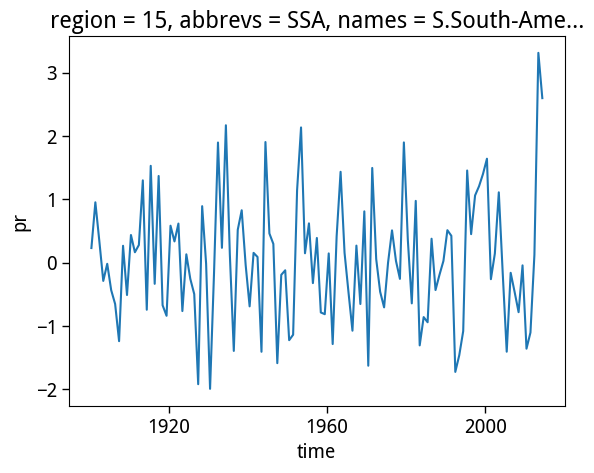

In [156]:
reg_std.plot()

In [157]:
sy, ey, sl, p, dur = get_all_tele(reg_std, nino34_index_hadisst, initial_dur=30)

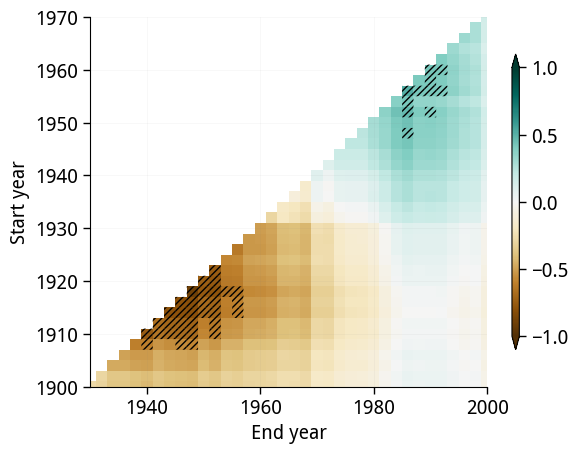

In [158]:
x, y = np.meshgrid(ey, sy)
cf = plt.pcolormesh(ey, sy, sl, cmap='BrBG', vmin=-1.0, vmax=1.0)
z = np.ma.masked_greater(p, 0.05)
plt.pcolor(x,y, z, hatch='/////', alpha=0.)
plt.colorbar(cf, shrink=0.8, extend='both', aspect=40)
# plt.gca().invert_yaxis()
plt.gca().invert_xaxis()
plt.ylabel('Start year')
plt.xlabel('End year')
plt.xlim(1930, 2000)
plt.ylim(1900, 1970)
plot_decorator()
# plt.savefig('./images/method/ssa_reg_temporal_tele_variation.png', dpi=300, bbox_inches='tight')

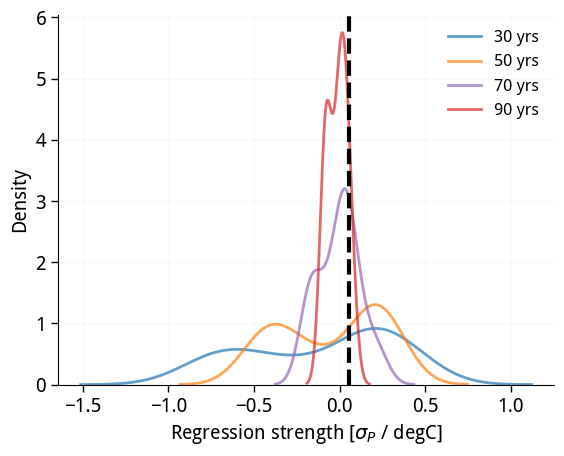

In [159]:
sns.kdeplot(sl[dur==30], alpha=0.7, lw=2.0, color='tab:blue', label='30 yrs')
sns.kdeplot(sl[dur==50], alpha=0.7, lw=2.0, color='tab:orange', label='50 yrs')
sns.kdeplot(sl[dur==70], alpha=0.7, lw=2.0, color='tab:purple', label='70 yrs')
sns.kdeplot(sl[dur==90], alpha=0.7, lw=2.0, color='tab:red', label='90 yrs')
plt.axvline(sl[dur==114], color='k', ls='--', lw=3.0)
plt.legend(frameon=False, fontsize=12)
plt.xlabel('Regression strength [$\sigma_P$ / degC]')
plot_decorator()
# plt.title('N. Australia [OBS]')

# plt.savefig('./images/method/ssa_reg_sample_size_effects.png', dpi=300, bbox_inches='tight')

In [160]:
pr_obs_ar6_variations = np.zeros((len(ar6_mask_rean), 43))
pr_rean_ar6_variations = np.zeros((len(ar6_mask_rean), 43))
ts_ar6_variations = np.zeros((len(ar6_mask_rean), 43))

for i in range(len(ar6_mask.region)):
    reg_det = pr_obs_det.where(ar6_mask.isel(region=i), drop=True).weighted(weights_pr_obs).mean(('lat', 'lon'))
    reg_std = reg_det/reg_det.std('time')
    sy, ey, sl, p, dur = get_all_tele(reg_std, nino34_index_hadisst, initial_dur=30)
    pr_obs_ar6_variations[i, :] = sl[dur == 30]
    #
    reg_det = pr_rean_det.where(ar6_mask_rean.isel(region=i), drop=True).weighted(weights_pr_rean).mean(('lat', 'lon'))
    reg_std = reg_det/reg_det.std('time')
    sy, ey, sl, p, dur = get_all_tele(reg_std, nino34_index_hadisst, initial_dur=30)
    pr_rean_ar6_variations[i, :] = sl[dur == 30]
    #
    reg_det = tas_obs_det.where(ar6_mask_ts.isel(region=i), drop=True).weighted(weights_obs).mean(('lat', 'lon'))
    sy, ey, sl, p, dur = get_all_tele(reg_det, nino34_index_hadisst, initial_dur=30)
    ts_ar6_variations[i, :] = sl[dur == 30]
    print(f'Completed {i + 1}/{len(ar6_mask_rean)}', end='\r')
    

In [161]:
pr_obs_ar6_variations_da = xr.DataArray(
    data=pr_obs_ar6_variations,
    dims=["region", "period"],
    coords=dict(
        lon=(["period"], np.arange(0, 43, 1)),
        lat=(["region"], ar6_mask.abbrevs.to_numpy()),
    ),
)

In [162]:
pr_rean_ar6_variations_da = xr.DataArray(
    data=pr_rean_ar6_variations,
    dims=["region", "period"],
    coords=dict(
        lon=(["period"], np.arange(0, 43, 1)),
        lat=(["region"], ar6_mask.abbrevs.to_numpy()),
    ),
)

In [163]:
ts_ar6_variations_da = xr.DataArray(
    data=ts_ar6_variations,
    dims=["region", "period"],
    coords=dict(
        lon=(["period"], np.arange(0, 43, 1)),
        lat=(["region"], ar6_mask.abbrevs.to_numpy()),
    ),
)

In [164]:
pr_obs_ar6_baselines = np.zeros((len(ar6_mask_rean)))
pr_rean_ar6_baselines = np.zeros((len(ar6_mask_rean)))
ts_ar6_baselines = np.zeros((len(ar6_mask_rean)))

for i in range(len(ar6_mask.region)):
    reg_det = pr_obs_det.where(ar6_mask.isel(region=i), drop=True).weighted(weights_pr_obs).mean(('lat', 'lon'))
    reg_std = reg_det/reg_det.std('time')
    sl, p, dur = calc_tele(reg_std, nino34_index_hadisst, start_year=1950, end_year=2014)
    pr_obs_ar6_baselines[i] = sl
    #
    reg_det = pr_rean_det.where(ar6_mask_rean.isel(region=i), drop=True).weighted(weights_pr_rean).mean(('lat', 'lon'))
    reg_std = reg_det/reg_det.std('time')
    sl, p, dur = calc_tele(reg_std, nino34_index_hadisst, start_year=1950, end_year=2014)
    pr_rean_ar6_baselines[i] = sl
    #
    reg_det = tas_obs_det.where(ar6_mask_ts.isel(region=i), drop=True).weighted(weights_obs).mean(('lat', 'lon'))
    sl, p, dur = calc_tele(reg_det, nino34_index_hadisst, start_year=1950, end_year=2014)
    ts_ar6_baselines[i] = sl
    print(f'Completed {i + 1}/{len(ar6_mask_rean)}', end='\r')
    

In [165]:
pr_obs_ar6_baselines_da = xr.DataArray(
    data=pr_obs_ar6_baselines,
    dims=["region"],
    coords=dict(
        region=(["region"], ar6_mask.abbrevs.to_numpy()),
    ),
)

In [166]:
pr_rean_ar6_baselines_da = xr.DataArray(
    data=pr_rean_ar6_baselines,
    dims=["region"],
    coords=dict(
        region=(["region"], ar6_mask.abbrevs.to_numpy()),
    ),
)

In [167]:
ts_ar6_baselines_da = xr.DataArray(
    data=ts_ar6_baselines,
    dims=["region"],
    coords=dict(
        region=(["region"], ar6_mask.abbrevs.to_numpy()),
    ),
)

In [168]:
pr_obs_ar6_total = np.zeros((len(ar6_mask_rean)))
pr_rean_ar6_total = np.zeros((len(ar6_mask_rean)))
ts_ar6_total = np.zeros((len(ar6_mask_rean)))

for i in range(len(ar6_mask.region)):
    reg_det = pr_obs_det.where(ar6_mask.isel(region=i), drop=True).weighted(weights_pr_obs).mean(('lat', 'lon'))
    reg_std = reg_det/reg_det.std('time')
    sl, p, dur = calc_tele(reg_std, nino34_index_hadisst, start_year=1900, end_year=2014)
    pr_obs_ar6_total[i] = sl
    #
    reg_det = pr_rean_det.where(ar6_mask_rean.isel(region=i), drop=True).weighted(weights_pr_rean).mean(('lat', 'lon'))
    reg_std = reg_det/reg_det.std('time')
    sl, p, dur = calc_tele(reg_std, nino34_index_hadisst, start_year=1900, end_year=2014)
    pr_rean_ar6_total[i] = sl
    #
    reg_det = tas_obs_det.where(ar6_mask_ts.isel(region=i), drop=True).weighted(weights_obs).mean(('lat', 'lon'))
    sl, p, dur = calc_tele(reg_det, nino34_index_hadisst, start_year=1900, end_year=2014)
    ts_ar6_total[i] = sl
    print(f'Completed {i + 1}/{len(ar6_mask_rean)}', end='\r')
    

In [169]:
pr_obs_ar6_total_da = xr.DataArray(
    data=pr_obs_ar6_total,
    dims=["region"],
    coords=dict(
        region=(["region"], ar6_mask.abbrevs.to_numpy()),
    ),
)

In [170]:
pr_rean_ar6_total_da = xr.DataArray(
    data=pr_rean_ar6_total,
    dims=["region"],
    coords=dict(
        region=(["region"], ar6_mask.abbrevs.to_numpy()),
    ),
)

In [171]:
ts_ar6_total_da = xr.DataArray(
    data=ts_ar6_total,
    dims=["region"],
    coords=dict(
        region=(["region"], ar6_mask.abbrevs.to_numpy()),
    ),
)

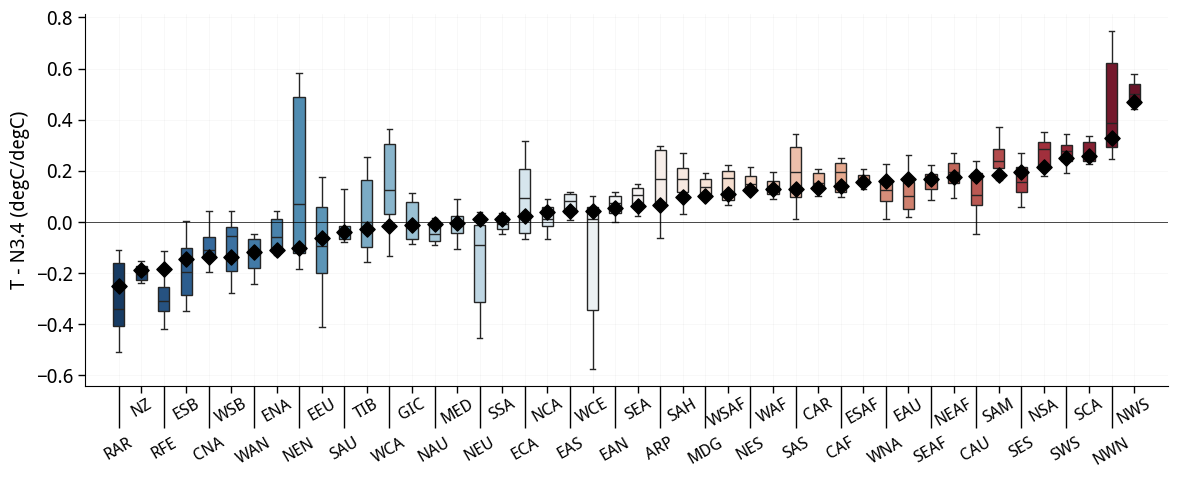

In [187]:
plt.figure(figsize=(12,5))
sns.boxplot(ts_ar6_variations_da.sortby(ts_ar6_baselines_da).to_dataframe(name = 'regr').reset_index(), x='region', y='regr', whis=[5,95], showfliers=False, notch=False, orient='v', palette='RdBu_r', width=0.5)
plt.scatter(np.arange(0,46,1), ts_ar6_baselines_da.sortby(ts_ar6_baselines_da).to_numpy(), marker='D', s=60, color='k', zorder=5)
# plt.scatter(np.arange(0,46,1), ts_ar6_baselines_da.sortby(ts_ar6_baselines_da).to_numpy(), marker='x', s=60, color='k', zorder=5)
plt.axhline(0.0, color='k', lw=0.5)
ax = plt.gca()
ax.set_xticklabels(ts_ar6_baselines_da.sortby(ts_ar6_baselines_da).region.to_numpy())
plt.xticks(rotation=30)
plot_decorator()
plt.ylabel('T - N3.4 (degC/degC)')
plt.xlabel('')
plt.xlim(-1.5, 46.5)

ax.tick_params(labelsize=12, axis='x')
ticks = ax.xaxis.get_major_ticks()
for i, tick in enumerate(ticks):
    if i % 2 == 0:
        # long tick
        tick.set_pad(30)
        tick.tick1line.set_markersize(30)  # Set custom length for alternate ticks
    else:
        tick.set_pad(2)
        tick.tick1line.set_markersize(5)

plt.tight_layout()

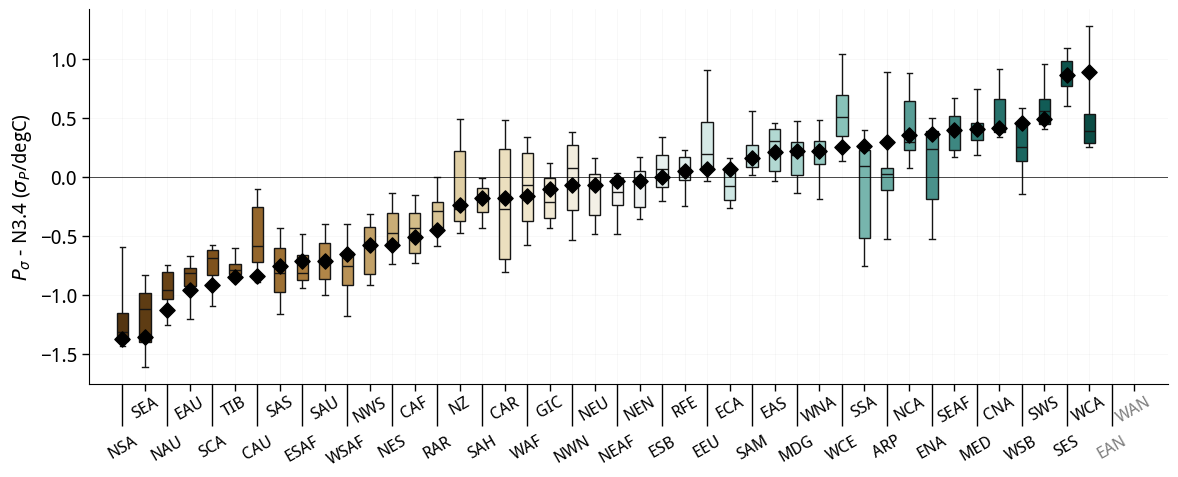

In [188]:
plt.figure(figsize=(12,5))
sns.boxplot(pr_obs_ar6_variations_da.sortby(pr_obs_ar6_baselines_da).to_dataframe(name = 'regr').reset_index(), x='region', y='regr', whis=[5,95], showfliers=False, notch=False, orient='v', palette='BrBG', width=0.5)
plt.scatter(np.arange(0,46,1), pr_obs_ar6_baselines_da.sortby(pr_obs_ar6_baselines_da).to_numpy(), marker='D', s=60, color='k', zorder=5)
# plt.scatter(np.arange(0,46,1), pr_obs_ar6_baselines_da.sortby(pr_obs_ar6_baselines_da).to_numpy(), marker='x', s=60, color='k', zorder=5)
plt.axhline(0.0, color='k', lw=0.5)
ax = plt.gca()
ax.set_xticklabels(pr_obs_ar6_baselines_da.sortby(pr_obs_ar6_baselines_da).region.to_numpy())
plt.xticks(rotation=30)
plot_decorator()
plt.ylabel('$P_{\sigma}$ - N3.4 ($\sigma_P$/degC)')
plt.xlabel('')
plt.xlim(-1.5, 46.5)

ax.tick_params(labelsize=12, axis='x')
ticks = ax.xaxis.get_major_ticks()
for i, tick in enumerate(ticks):
    if i % 2 == 0:
        # long tick
        tick.set_pad(30)
        tick.tick1line.set_markersize(30)  # Set custom length for alternate ticks
    else:
        tick.set_pad(2)
        tick.tick1line.set_markersize(5)

plt.tight_layout()
# plt.axvspan(44,45, color='tab:gray', alpha=0.4, lw=0.)
labels = ax.get_xticklabels()

# Set color for the last two
labels[-1].set_color('tab:gray')
labels[-2].set_color('tab:gray')

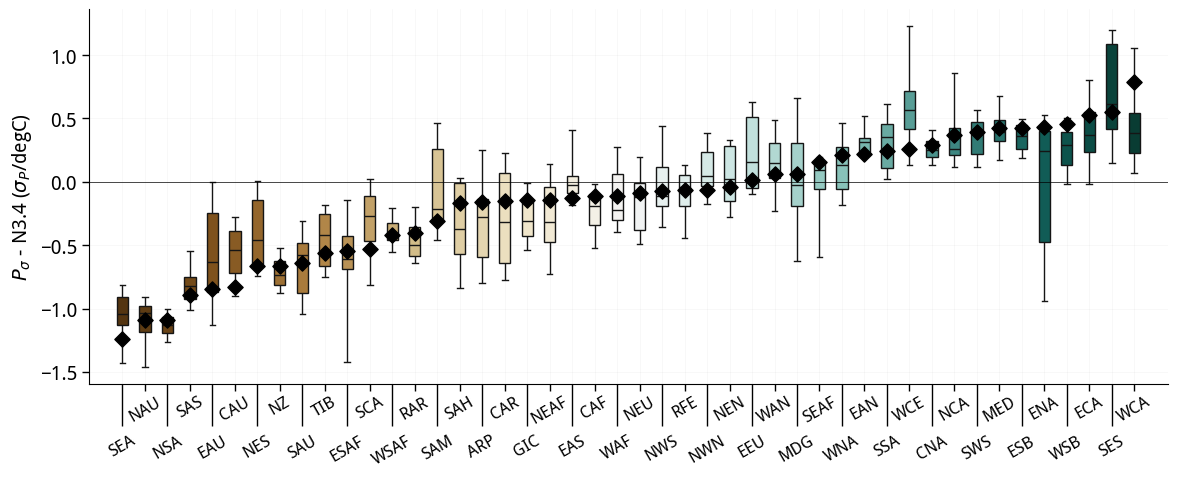

In [189]:
plt.figure(figsize=(12,5))
sns.boxplot(pr_rean_ar6_variations_da.sortby(pr_rean_ar6_baselines_da).to_dataframe(name = 'regr').reset_index(), x='region', y='regr', whis=[5,95], showfliers=False, notch=False, orient='v', palette='BrBG', width=0.5)
plt.scatter(np.arange(0,46,1), pr_rean_ar6_baselines_da.sortby(pr_rean_ar6_baselines_da).to_numpy(), marker='D', s=60, color='k', zorder=5)
# plt.scatter(np.arange(0,46,1), pr_rean_ar6_baselines_da.sortby(pr_rean_ar6_baselines_da).to_numpy(), marker='x', s=60, color='k', zorder=5)
plt.axhline(0.0, color='k', lw=0.5)
ax = plt.gca()
ax.set_xticklabels(pr_rean_ar6_baselines_da.sortby(pr_rean_ar6_baselines_da).region.to_numpy())
plt.xticks(rotation=30)
plot_decorator()
plt.ylabel('$P_{\sigma}$ - N3.4 ($\sigma_P$/degC)')
plt.xlabel('')
plt.xlim(-1.5, 46.5)

ax.tick_params(labelsize=12, axis='x')
ticks = ax.xaxis.get_major_ticks()
for i, tick in enumerate(ticks):
    if i % 2 == 0:
        # long tick
        tick.set_pad(30)
        tick.tick1line.set_markersize(30)  # Set custom length for alternate ticks
    else:
        tick.set_pad(2)
        tick.tick1line.set_markersize(5)

plt.tight_layout()

Text(0.5, 1.0, 'AR6 Regions')

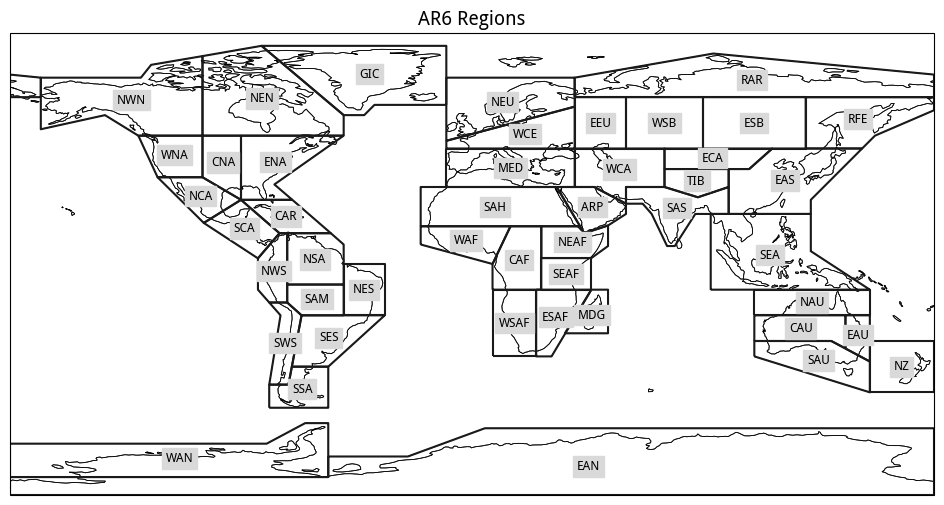

In [191]:
# Load AR6 regions
regions = regionmask.defined_regions.ar6.land

# Plot using regionmask's built-in plotting
fig, ax = plt.subplots(
    figsize=(12,6),
    subplot_kw=dict(projection=ccrs.PlateCarree(central_longitude=0))
)

# Plot regions (no numeric labels)
regions.plot(
    ax=ax,
    add_label=False,
    line_kws=dict(linewidth=0.6, color='black')
)

# Add abbreviations (centered labels)
regions.plot(
    ax=ax,
    add_label=True,
    label='abbrev',   # ensures abbreviations instead of numbers
    text_kws=dict(
        fontsize=9,
        ha='center',
        va='center',
    ),
    # add_ocean=True,
)

# Clean up
ax.coastlines(linewidth=0.6)
# ax.add_feature(cfeature.OCEAN, color='tab:blue', zorder=0)
ax.set_global()
ax.set_title("AR6 Regions", fontsize=14)